# 04 - UHI hotspots and tree-planting priority

Where the heat islands are, and where planting trees first would help most.

In [1]:
import sys
from pathlib import Path

# notebooks live one level below the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config
from src.data import db as db_mod

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
%matplotlib inline


In [2]:
cfg = load_config(ROOT / 'config.yaml')
engine = db_mod.get_engine(cfg)
grid = db_mod.read_table(engine, 'grid_cells')

## UHI intensity and hotspots

In [3]:
print('hotspot cells:', int(grid['is_hotspot'].sum()))
print('coldspot cells:', int((grid['is_hotspot'] == 0).sum()))
print('mean UHI:', round(grid['uhi_intensity'].mean(), 3))
print('max UHI:', round(grid['uhi_intensity'].max(), 3))

hotspot cells: 598
coldspot cells: 1902
mean UHI: 0.7
max UHI: 9.086


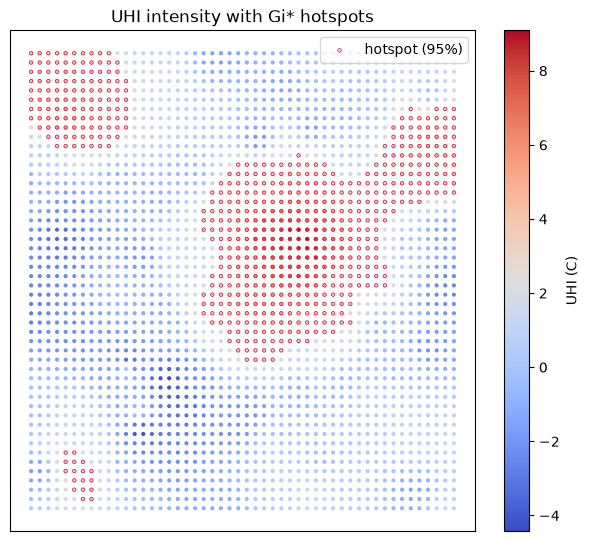

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sc = ax.scatter(grid['centroid_x'], grid['centroid_y'], c=grid['uhi_intensity'],
                cmap='coolwarm', s=4)
hot = grid[grid['is_hotspot'] == 1]
ax.scatter(hot['centroid_x'], hot['centroid_y'], s=6, facecolors='none',
           edgecolors='#e11d48', linewidths=0.6, label='hotspot (95%)')
ax.set_title('UHI intensity with Gi* hotspots'); ax.legend()
ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(sc, label='UHI (C)'); plt.show()

## Ward ranking for tree planting

In [5]:
db_mod.read_table(engine, 'ward_summary').round(4)

,ward_id,mean_temp,mean_uhi,mean_ndvi,mean_builtup,hotspot_area_pct,priority_score,priority_rank
0,W10,28.4491,2.8160,0.2620,0.7938,68.4211,0.6112,1
1,W17,29.3311,3.6980,0.3246,0.5651,81.3559,0.5542,2
2,W11,31.5339,5.9008,0.4597,0.3426,100.0000,0.5216,3
3,W04,28.3345,2.7014,0.4433,0.1258,70.6587,0.3656,4
4,W14,25.5709,-0.0621,0.6395,0.2728,4.2056,0.2825,5
5,W07,26.0918,0.4587,0.6058,0.1309,14.2857,0.2632,6
6,W15,27.3334,1.7004,0.7696,0.1031,51.9553,0.2538,7
7,W01,25.9092,0.2761,0.6255,0.1214,8.9947,0.2504,8
8,W16,27.6403,2.0072,0.7429,0.0000,42.7746,0.2381,9
9,W13,25.9172,0.2841,0.7203,0.1164,0.0000,0.2272,10


## Top priority cells

In [6]:
cols = ['cell_id', 'ward_id', 'temp_idw', 'uhi_intensity', 'ndvi_mean',
        'builtup_frac', 'landcover_class', 'priority_score', 'priority_rank']
grid.nsmallest(20, 'priority_rank')[cols].round(3)

,cell_id,ward_id,temp_idw,uhi_intensity,ndvi_mean,builtup_frac,landcover_class,priority_score,priority_rank
1380,1380,W11,33.591,7.958,0.146,0.875,built_up,0.815,1
1379,1379,W11,33.368,7.735,0.130,0.867,built_up,0.809,2
1381,1381,W11,33.702,8.069,0.167,0.859,built_up,0.808,3
1132,1132,W10,30.704,5.071,-0.033,1.000,built_up,0.808,4
1182,1182,W10,30.836,5.203,-0.012,1.000,built_up,0.807,5
1179,1179,W10,31.100,5.467,0.030,1.000,built_up,0.805,6
1178,1178,W10,31.212,5.579,0.056,1.000,built_up,0.802,7
1378,1378,W11,33.174,7.541,0.124,0.855,built_up,0.801,8
1181,1181,W10,30.694,5.061,-0.006,1.000,built_up,0.801,9
1180,1180,W10,30.794,5.161,0.009,1.000,built_up,0.801,10


## Where the hotspots sit by land cover

In [7]:
grid.groupby('landcover_class').agg(
    cells=('cell_id', 'size'),
    hotspot_pct=('is_hotspot', lambda s: round(100 * s.mean(), 1)),
    mean_uhi=('uhi_intensity', 'mean'),
).round(2)

,cells,hotspot_pct,mean_uhi
landcover_class,,,
built_up,306,69.9,3.56
cropland,6,0.0,0.39
grassland,124,27.4,1.47
tree_cover,1964,15.9,0.15
water,100,37.0,1.82


**Read this.** Hotspots should sit on built-up land in the core, and the priority ranking should point at hot, bare, built-up cells. If a hotspot landed on the lake or a park, something would be wrong.